# Ejercicio 05 · Motor recomendador reproducible

INF-8239 Ciencia de Datos II · Unidad 03 · LAB08 y LAB09. Estudiante: Raimi De Jesús (hkh25487).

Este cuaderno reúne la evidencia de LAB08 y LAB09: datos y auditoría, corte temporal, popularidad, contenido, factorización matricial, híbrido, decisión de Pareto, usuarios fríos y límites. Las partes rápidas (auditoría, contenido) se calculan aquí; el entrenamiento de tres semillas (unos 5 minutos) lo hace `scripts/lab09_compare.py` y este cuaderno lee sus resultados de `reports/`.

Reproducción: `uv sync`, `uv run python scripts/download_data.py`, `uv run python scripts/lab09_compare.py` y luego ejecutar este cuaderno.

In [1]:
import json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from inf8239_u03.config import MOVIELENS_DIR, ROOT
from inf8239_u03.data import load_movielens
from inf8239_u03.recommenders import ContentRecommender, temporal_leave_one_out

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)
REPORTS = ROOT / "reports"
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

Python 3.12.14 | pandas 2.3.3 | numpy 2.5.3 | scikit-learn 1.9.1


## 1. Datos, licencia y auditoría
MovieLens Latest Small (GroupLens, Universidad de Minnesota). Uso académico; **los datos no se redistribuyen** (`data/raw/` no está en Git). Cita: Harper y Konstan (2015), DOI 10.1145/2827872. Ficha completa en `docs/DATASET_CARD.md`.

In [2]:
ratings, movies = load_movielens(MOVIELENS_DIR)   # valida columnas, películas huérfanas y rango de ratings
n_users, n_movies = ratings["userId"].nunique(), len(movies)
print(f"Valoraciones: {len(ratings):,} | usuarios: {n_users} | películas en catálogo: {n_movies:,} | con valoración: {ratings['movieId'].nunique():,}")
print("Rango temporal (UTC):", pd.to_datetime(ratings["timestamp"], unit="s").min().date(), "a", pd.to_datetime(ratings["timestamp"], unit="s").max().date())
print(f"Densidad: {len(ratings) / (n_users * n_movies):.5f}")
display(ratings["rating"].describe().round(3).to_frame().T)
card = (ROOT / "docs" / "DATASET_CARD.md").read_text(encoding="utf-8")
print([line.strip() for line in card.splitlines() if "SHA-256 del archivo zip" in line])

Valoraciones: 100,836 | usuarios: 610 | películas en catálogo: 9,742 | con valoración: 9,724
Rango temporal (UTC): 1996-03-29 a 2018-09-24
Densidad: 0.01697


,count,mean,std,min,25%,50%,75%,max
rating,100836.0,3.502,1.043,0.5,3.0,3.5,4.0,5.0


['- **SHA-256 del archivo zip descargado:** `696d65a3dfceac7c45750ad32df2c259311949efec81f0f144fdfb91ebc9e436` (calculado por `scripts/download_data.py`).']


## 2. Corte temporal
Se reserva la última valoración de cada usuario para prueba (leave-one-out temporal). Los modelos solo ven el entrenamiento.

In [3]:
train, test = temporal_leave_one_out(ratings)
print(f"Entrenamiento: {len(train):,} | prueba: {len(test):,} (una por usuario)")
last_train = train.groupby("userId")["timestamp"].max()
held = test.groupby("userId")["timestamp"].min()
tied = int((last_train.reindex(held.index) >= held).sum())
print(f"Usuarios cuya valoración reservada NO es estrictamente posterior a su última de entrenamiento: {tied} de {len(held)}")
diag = json.loads((REPORTS / "lab09_diagnostics.json").read_text(encoding="utf-8"))
print("Evaluables (usuario y película vistos en entrenamiento):", diag["evaluable_rows"], "| con corte estrictamente posterior:", diag["users_with_strictly_later_heldout"])

Entrenamiento: 100,226 | prueba: 610 (una por usuario)


Usuarios cuya valoración reservada NO es estrictamente posterior a su última de entrenamiento: 94 de 610
Evaluables (usuario y película vistos en entrenamiento): 587 | con corte estrictamente posterior: 516


## 3. Popularidad y contenido (LAB08)
Popularidad ponderada: la media de cada película se acerca a la media global cuando tiene pocas valoraciones. Contenido: TF-IDF sobre géneros y similitud coseno; la película consultada no aparece en su propia lista.

In [4]:
pop = pd.read_csv(REPORTS / "popular_top10.csv", index_col=0)
display(pop.round(3))

,title,count,mean,weighted_score
movieId,,,,
318,"Shawshank Redemption, The (1994)",317,4.429,4.395
858,"Godfather, The (1972)",192,4.289,4.243
2959,Fight Club (1999),218,4.273,4.233
260,Star Wars: Episode IV - A New Hope (1977),251,4.231,4.198
50,"Usual Suspects, The (1995)",204,4.238,4.197
1221,"Godfather: Part II, The (1974)",129,4.260,4.195
527,Schindler's List (1993),220,4.225,4.188
1213,Goodfellas (1990),126,4.250,4.185
750,Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964),97,4.268,4.184


In [5]:
QUERIES = ["Toy Story (1995)", "Pulp Fiction (1994)", "Alien (1979)", "Schindler's List (1993)"]
content = ContentRecommender().fit(movies)
for title in QUERIES:
    rec = content.recommend(title, 10)
    ties = int((rec["content_score"].round(6) == 1.0).sum())
    print(f"\n{title}: {ties} de 10 resultados con puntuación 1,0 (empate)")
    display(rec[["title", "genres", "content_score"]].round(4).head(5))


Toy Story (1995): 10 de 10 resultados con puntuación 1,0 (empate)


,title,genres,content_score
0,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
2,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
4,Asterix and the Vikings (Astérix et les Vikings) (2006),Adventure|Animation|Children|Comedy|Fantasy,1.0



Pulp Fiction (1994): 9 de 10 resultados con puntuación 1,0 (empate)

,title,genres,content_score
0,Confessions of a Dangerous Mind (2002),Comedy|Crime|Drama|Thriller,1.0
1,"Informant!, The (2009)",Comedy|Crime|Drama|Thriller,1.0
2,Leaves of Grass (2009),Comedy|Crime|Drama|Thriller,1.0
3,Freeway (1996),Comedy|Crime|Drama|Thriller,1.0
4,In Bruges (2008),Comedy|Crime|Drama|Thriller,1.0



Alien (1979): 10 de 10 resultados con puntuación 1,0 (empate)


,title,genres,content_score
0,Swamp Thing (1982),Horror|Sci-Fi,1.0
1,Village of the Damned (1995),Horror|Sci-Fi,1.0
2,Attack of the Puppet People (1958),Horror|Sci-Fi,1.0
3,Attack of the Crab Monsters (1957),Horror|Sci-Fi,1.0
4,"Faculty, The (1998)",Horror|Sci-Fi,1.0



Schindler's List (1993): 10 de 10 resultados con puntuación 1,0 (empate)


,title,genres,content_score
0,Come and See (Idi i smotri) (1985),Drama|War,1.0
1,"Children of Huang Shi, The (2008)",Drama|War,1.0
2,Stop-Loss (2008),Drama|War,1.0
3,Che: Part Two (2008),Drama|War,1.0
4,Che: Part One (2008),Drama|War,1.0


**Lectura.** La similitud mide coincidencia de géneros. Cuando varios resultados empatan en 1,0, su orden no tiene significado, y la lista no distingue calidad, época ni popularidad (sobre-especialización).

## 4. Resultados de LAB09
Tres semillas (42, 7, 123), 20 factores, 12 épocas, α ∈ {0,25; 0,75}. Métricas: RMSE (valoraciones), HitRate@10 (ranking), cobertura de catálogo y costo en segundos.

In [6]:
summary = pd.read_csv(REPORTS / "lab09_summary.csv")
display(summary.round(4))

,method,hit_rate_mean,hit_rate_std,hit_rate_strict_mean,coverage_mean,cost_seconds_mean,rmse_mean,rmse_std,pareto
0,azar_esperado,0.0010,0.0000,NaN,NaN,0.0000,NaN,NaN,False
1,colaborativo,0.0352,0.0055,0.0357,0.0701,41.8363,1.0261,0.0003,False
2,contenido,0.0017,0.0000,0.0020,0.0778,4.1639,NaN,NaN,True
3,hibrido_a0.25,0.0267,0.0052,0.0263,0.1015,41.8363,1.0261,0.0003,True
4,hibrido_a0.75,0.0352,0.0055,0.0343,0.0723,41.8363,1.0261,0.0003,True
5,popularidad,0.0426,0.0000,0.0384,0.0122,0.0065,NaN,NaN,True


In [7]:
n = diag["evaluable_rows"]
rmse_mf = summary.loc[summary["method"] == "colaborativo", "rmse_mean"].iloc[0]
print(f"RMSE factorización: {rmse_mf:.4f} | media global: {diag['rmse_global_mean']:.4f} | media por película: {diag['rmse_item_mean']:.4f}")
for method in ["popularidad", "colaborativo", "hibrido_a0.75"]:
    p = summary.loc[summary["method"] == method, "hit_rate_mean"].iloc[0]
    print(f"{method:15s} HitRate@10 = {p:.4f} (≈ {p * n:.0f} aciertos de {n}), error típico binomial ≈ {np.sqrt(p * (1 - p) / n):.4f}")

RMSE factorización: 1.0261 | media global: 1.1157 | media por película: 1.0503
popularidad     HitRate@10 = 0.0426 (≈ 25 aciertos de 587), error típico binomial ≈ 0.0083
colaborativo    HitRate@10 = 0.0352 (≈ 21 aciertos de 587), error típico binomial ≈ 0.0076
hibrido_a0.75   HitRate@10 = 0.0352 (≈ 21 aciertos de 587), error típico binomial ≈ 0.0076


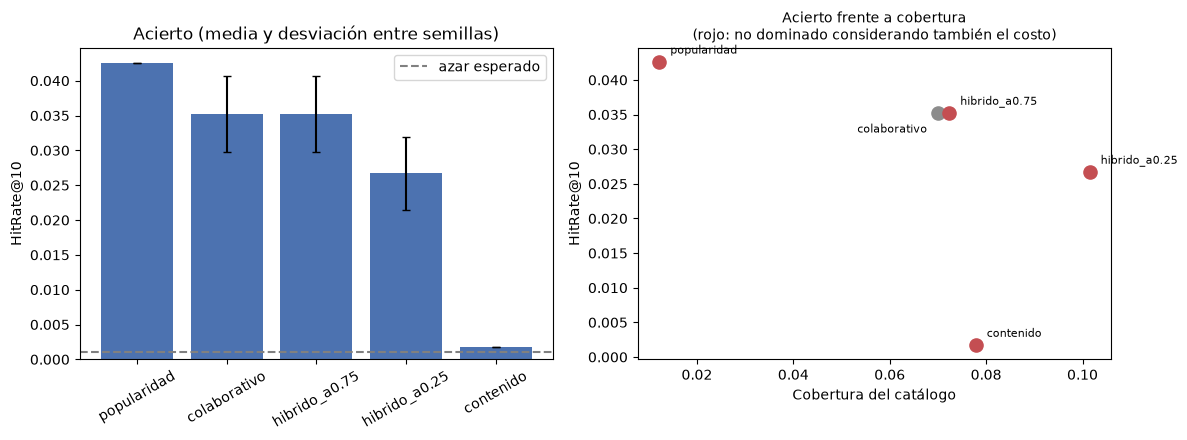

In [8]:
real = summary[summary["method"] != "azar_esperado"].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
order = real.sort_values("hit_rate_mean", ascending=False)
ax.bar(order["method"], order["hit_rate_mean"], yerr=order["hit_rate_std"].fillna(0), color="#4C72B0", capsize=3)
ax.axhline(summary.loc[summary["method"] == "azar_esperado", "hit_rate_mean"].iloc[0], color="gray", ls="--", label="azar esperado")
ax.set_ylabel("HitRate@10"); ax.set_title("Acierto (media y desviación entre semillas)"); ax.legend()
ax.tick_params(axis="x", rotation=30)
ax = axes[1]
offsets = {"colaborativo": (-8, -14, "right"), "hibrido_a0.75": (8, 6, "left")}
for row in real.itertuples():
    ax.scatter(row.coverage_mean, row.hit_rate_mean, s=90, color="#C44E52" if row.pareto else "#8C8C8C")
    dx, dy, ha = offsets.get(row.method, (8, 6, "left"))
    ax.annotate(row.method, (row.coverage_mean, row.hit_rate_mean), textcoords="offset points", xytext=(dx, dy), ha=ha, fontsize=8)
ax.set_xlabel("Cobertura del catálogo"); ax.set_ylabel("HitRate@10")
ax.set_title("Acierto frente a cobertura\n(rojo: no dominado considerando también el costo)", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura.**
- Popularidad, colaborativo e híbrido α = 0,75 no se distinguen en acierto: la diferencia está dentro del error típico binomial. El contenido solo no supera al azar de forma útil.
- Más peso al contenido (α = 0,25) aumenta la cobertura y baja el acierto.
- Pareto (acierto, cobertura, costo): quedan sin dominar popularidad, contenido (solo por cobertura), híbrido 0,25 e híbrido 0,75. El colaborativo puro lo domina el híbrido 0,75 por una diferencia mínima de cobertura.
- La factorización mejora el RMSE de las dos medias de referencia, aunque solo un 2,3 % la de la media por película.

## 5. Perfiles y usuarios fríos

In [9]:
profiles = pd.read_csv(REPORTS / "lab09_profiles.csv")
display(profiles[["profile", "userId", "n_train", "method", "held_out", "hit"]])
fallback = profiles[profiles["profile"].str.startswith("usuario nuevo")]
print("Respaldo para usuario sin historial:", fallback["top10"].iloc[0])

,profile,userId,n_train,method,held_out,hit
0,historial amplio,414,2697,popularidad,The Greatest Showman (2017),0.0
1,historial amplio,414,2697,contenido,The Greatest Showman (2017),0.0
2,historial amplio,414,2697,colaborativo,The Greatest Showman (2017),0.0
3,historial amplio,414,2697,hibrido_a0.25,The Greatest Showman (2017),0.0
4,historial amplio,414,2697,hibrido_a0.75,The Greatest Showman (2017),0.0
5,historial corto,53,19,popularidad,When a Man Loves a Woman (1994),0.0
6,historial corto,53,19,contenido,When a Man Loves a Woman (1994),0.0
7,historial corto,53,19,colaborativo,When a Man Loves a Woman (1994),0.0
8,historial corto,53,19,hibrido_a0.25,When a Man Loves a Woman (1994),0.0
9,historial corto,53,19,hibrido_a0.75,When a Man Loves a Woman (1994),0.0


Respaldo para usuario sin historial: Forrest Gump (1994) | Shawshank Redemption, The (1994) | Pulp Fiction (1994) | Matrix, The (1999) | Silence of the Lambs, The (1991) | Star Wars: Episode IV - A New Hope (1977) | Braveheart (1995) | Jurassic Park (1993) | Terminator 2: Judgment Day (1991) | Fight Club (1999)


## 6. Decisión, límites y riesgos
**Decisión propuesta:** híbrido α = 0,75 con respaldo de popularidad para usuarios sin historial. Iguala en acierto a la popularidad dentro del error de medición y cubre unas seis veces más del catálogo (7,2 % frente a 1,2 %). **No se demostró una mejora de acierto sobre la popularidad.**

**Límites:**
- Una sola película reservada por usuario hace que HitRate@10 sea bajo y ruidoso.
- Para 94 de 610 usuarios la valoración reservada comparte fecha y hora con la última de entrenamiento; con el corte estricto las conclusiones no cambian.
- 23 usuarios no son evaluables porque su película reservada no tiene valoraciones de entrenamiento.
- Datos de 2018, densidad de 1,7 % y sin demografía: no permiten concluir nada sobre grupos.
- Los tiempos varían entre ejecuciones y son orientativos.

**Riesgo principal y mitigación:** afirmar mejoras que la evaluación no sostiene. Mitigación: reportar error típico y corte estricto, no afirmar superioridad sobre la popularidad y repetir con más películas reservadas antes de cualquier uso real. Detalle en `docs/SYSTEM_CARD.md` e `docs/INTERPRETACION_LAB08_LAB09.md`.